# Doku fotoğrafın içinde ne kadar değişiyor?

Önceki üç komşu modeline tek bir bilgi ekliyoruz. Her fiziksel ölçekte 16 bölgenin doku değerlerinin standart sapmasını hesaplıyoruz. Değer yüksekse bölgelerin dokuları birbirinden daha farklı. Her numuneyi sırayla dışarıda bırakarak iki yöntemi aynı fotoğraflarda karşılaştırıyoruz.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from sklearn.preprocessing import StandardScaler

root = Path("/kaggle/input") if Path("/kaggle/input").exists() else Path("work/soil-data")
data = next(root.rglob("Training_labels_updated.csv")).parent
labels = pd.read_csv(data / "Training_labels_updated.csv").set_index("sample_id")
cameras = pd.read_csv(data / "ppm_updated.csv")
photos = sorted(data.joinpath("Training-All_Photos_updated").rglob("*.jpg"))
print(f"{len(labels)} numune, {len(photos)} eğitim fotoğrafı")

24 numune, 127 eğitim fotoğrafı


In [2]:
def physical_patch(path, camera):
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image)
        w, h = image.size
        pixels_per_mm = camera.ppm * max(w, h) / max(camera.width, camera.height)
        side = round(100 * pixels_per_mm)
        assert 0 < side <= min(w, h)
        x, y = (w - side) // 2, (h - side) // 2
        return image.crop((x, y, x + side, y + side)).convert("RGB").resize((400, 400), Image.Resampling.LANCZOS)


def normalized_gray(patch):
    gray = np.asarray(patch.convert("L"), dtype=float)
    low, high = np.percentile(gray, [5, 95])
    return np.clip((gray - low) / max(high - low, 1.0), 0, 1)

def texture_at_six_scales(gray):
    values = []
    for offset in [1, 2, 4, 8, 16, 32]:
        x = np.abs(gray[:, offset:] - gray[:, :-offset]).mean()
        y = np.abs(gray[offset:, :] - gray[:-offset, :]).mean()
        values.append((x + y) / 2)
    return values

cameras_by_name = {c.phone.replace(" ", "_").lower(): c for c in cameras.itertuples()}
feature_rows = []
for path in photos:
    phone, sample, _ = path.stem.rsplit("_", 2)
    patch = physical_patch(path, cameras_by_name[phone.lower()])
    gray = normalized_gray(patch)
    regions = [gray[y:y+100, x:x+100] for y in range(0, 400, 100) for x in range(0, 400, 100)]
    region_textures = np.array([texture_at_six_scales(region) for region in regions])
    spread = region_textures.std(axis=0)
    feature_rows.append([sample, *texture_at_six_scales(gray), *spread])
    if path.stem == "Motorola_Edge_H038_03":
        example = patch.copy()

scales = ["0.25", "0.5", "1", "2", "4", "8"]
columns = scales + ["sd_" + s for s in scales]
frame = pd.DataFrame(feature_rows, columns=["sample_id", *columns])
features = frame.groupby("sample_id").median().loc[labels.index]
assert features.shape == (24, 12) and np.isfinite(features).all().all()

## İki yöntemin yerel sınavı

Üç komşuyu bulmadan önce doku ölçülerini yalnızca geride kalan 23 numune üzerinden standartlaştırıyoruz. Her numuneye bir oy veriyoruz. Bir numunenin bütün çekimleri aynı tarafta kalıyor. EMD küçüldükçe laboratuvar eğrisine daha çok yaklaşıyoruz.

In [3]:
sizes = labels.columns.astype(float).to_numpy()
widths = np.diff(np.log10(sizes))
predictions, errors = {}, {}
for name, keys in [("Önceki", scales), ("Bölgeli", columns)]:
    curves = []
    for sample in labels.index:
        train = features[keys].drop(index=sample)
        scaler = StandardScaler().fit(train)
        delta = scaler.transform(train) - scaler.transform(features.loc[[sample], keys])
        nearest = train.index[np.argsort(np.linalg.norm(delta, axis=1), kind="stable")[:3]]
        assert sample not in nearest and len(set(nearest)) == 3
        curves.append(labels.loc[nearest].mean())
    predicted = pd.DataFrame(curves, index=labels.index)
    assert np.all(np.diff(predicted, axis=1) >= -1e-9) and predicted["200"].eq(100).all()
    predictions[name] = predicted
    errors[name] = np.abs((predicted - labels).to_numpy()[:, :-1]) @ widths

scores = pd.DataFrame(errors, index=labels.index)
change = scores["Bölgeli"] - scores["Önceki"]
assert round(scores["Önceki"].mean(), 2) == 44.74
print(scores.round(2).to_string())
print("Ortalama EMD", scores.mean().round(3).to_dict())
print("H038 hariç ortalama EMD", scores.drop("H038").mean().round(3).to_dict())
same = np.isclose(change, 0)
print("İyileşen / kötüleşen / aynı:", sum((change < 0) & ~same), sum((change > 0) & ~same), sum(same))
values = {name: pred.loc["H038", "2"] for name, pred in predictions.items()}
print("H038 • 2 mm altı (%)", {**values, "Laboratuvar": labels.loc["H038", "2"]})

           Önceki  Bölgeli
sample_id                 
F827        63.98   116.35
G190        24.85    23.34
H030        44.43    21.38
H037        60.27    86.32
H038        93.28   138.95
H126        14.28    20.03
H181        20.89    27.41
H183        28.41    17.65
H366         8.11    13.70
H367         7.67    12.59
H368        14.50    13.49
H371        14.03    12.97
H372         7.27    13.20
H374       128.87    21.44
H405       133.53    64.67
H493        27.70    60.24
H516        90.35   141.27
H549        13.97    11.53
H615        11.57    13.52
H616        85.30    85.30
H617        71.29    35.76
H637        40.53    40.53
H666        35.08    35.08
H668        33.70    33.70
Ortalama EMD {'Önceki': 44.744, 'Bölgeli': 44.184}
H038 hariç ortalama EMD {'Önceki': 42.633, 'Bölgeli': 40.064}
İyileşen / kötüleşen / aynı: 9 11 4
H038 • 2 mm altı (%) {'Önceki': np.float64(85.14643333333333), 'Bölgeli': np.float64(87.05686666666668), 'Laboratuvar': np.float64(47.2345)}


## H038’de model hangi alanları gördü?

Solda sekiz çekimden birinde kullanılan yaklaşık 10 × 10 cm kesit var. Sağdaki tahmin, numunenin bütün çekimlerinden hesaplandı.

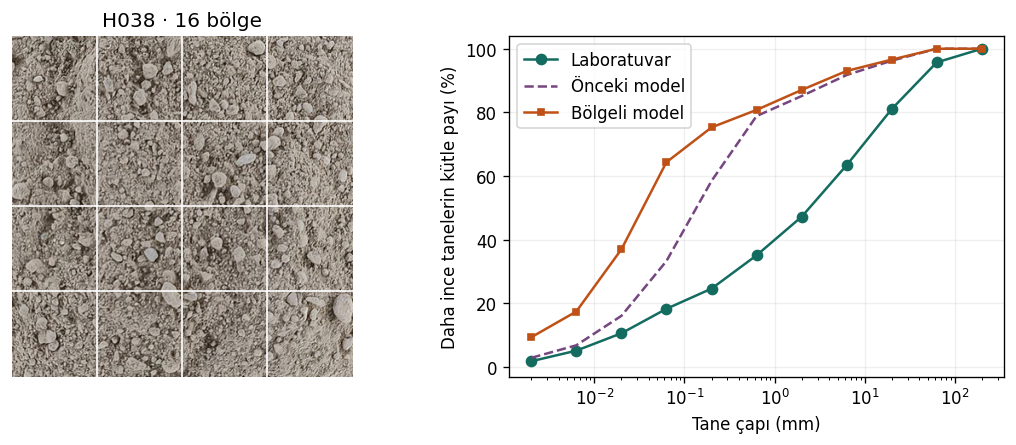

In [4]:
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.6), layout="constrained")
left.imshow(example)
for edge in [99.5, 199.5, 299.5]:
    left.axhline(edge, color="white", linewidth=1)
    left.axvline(edge, color="white", linewidth=1)
left.set(title="H038 · 16 bölge")
left.set_axis_off()
right.semilogx(sizes, labels.loc["H038"], "o-", label="Laboratuvar", color="#146b60")
right.semilogx(sizes, predictions["Önceki"].loc["H038"], "--", label="Önceki model", color="#75467f")
right.semilogx(sizes, predictions["Bölgeli"].loc["H038"], "s-", label="Bölgeli model", color="#bf5117", markersize=4)
right.set(xlabel="Tane çapı (mm)", ylabel="Daha ince tanelerin kütle payı (%)", ylim=(-3, 104))
right.grid(alpha=0.2)
right.legend()
plt.show()